# SegFormer-B0: análisis del ajuste fino

El proceso conserva auditoría, entrenamiento en dos fases, selección por validación y evaluación en prueba. La tarea cambia de una etiqueta por imagen a una etiqueta por píxel. Los artefactos se generan con `train.py`; el cuaderno no realiza entrenamiento.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

project = Path.cwd().resolve()
candidates = [project, project / 'deep_learning/02_seguimiento_carril_segformer',
              project / '02_seguimiento_carril_segformer', *project.parents]
project = next((p for p in candidates if (p / 'segformer_utils.py').is_file()), None)
if project is None:
    raise FileNotFoundError('Abrir el cuaderno desde el proyecto o la raíz del repositorio del curso.')
sys.path.insert(0, str(project))
RUN_NAME = 'segformer_b0_clase'  # Nombre del experimento que se analizará.
run = Path(os.environ.get('VISION_RUN_DIR', project / 'runs' / RUN_NAME)).resolve()
if not (run / 'metrics.json').is_file():
    raise FileNotFoundError(f'Completar el entrenamiento o ajustar RUN_NAME: {run}')
config = json.loads((run / 'config.json').read_text(encoding='utf-8'))
metrics = json.loads((run / 'metrics.json').read_text(encoding='utf-8'))
history = pd.read_csv(run / 'history.csv')
predictions = pd.read_csv(run / 'test_predictions.csv')
dataset = Path(config['data'])
if not dataset.is_dir():
    dataset = project / 'data' / dataset.name
if not dataset.is_dir():
    raise FileNotFoundError('No se encontró el dataset utilizado para entrenar.')
display(pd.Series({'Modelo': config['model'], 'Pesos iniciales': config['pretrained'], 'Dispositivo': config['cuda_device'] or config['device'], 'Mejor época': metrics['best_epoch'], 'IoU media de validación': metrics['best_val_mean_iou'], 'Tiempo de entrenamiento [s]': metrics['training_seconds']}, name='Experimento').to_frame())

,Experimento
Modelo,segformer_b0
Pesos iniciales,nvidia/mit-b0
Dispositivo,NVIDIA T1000 8GB
Mejor época,15
IoU media de validación,0.99921
Tiempo de entrenamiento [s],906.732968


## Verificación de etiquetas
Las máscaras originales guardan 0 y 1, por lo que pueden verse negras en un visor de 0 a 255. La visualización fija `vmin=0, vmax=1`. No cambiar las etiquetas del entrenamiento para mejorar su contraste.

Valores y conteos: (array([0, 1], dtype=uint8), array([22979, 38461]))


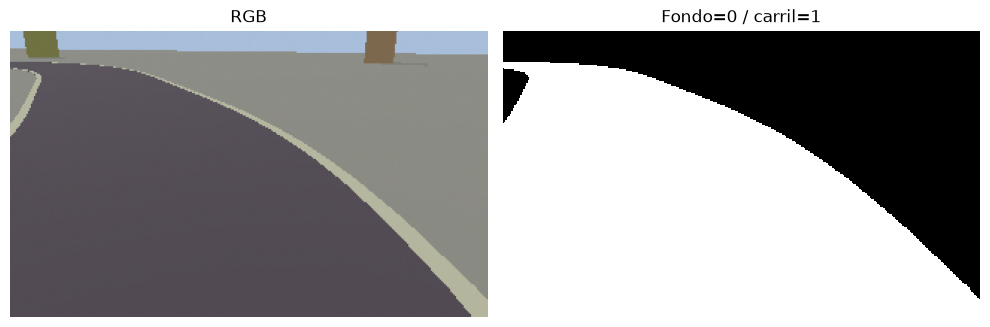

In [2]:
row = predictions.iloc[0]
rgb = np.asarray(Image.open(dataset / row.image).convert('RGB'))
mask = np.asarray(Image.open(dataset / row.ground_truth))
assert set(np.unique(mask)).issubset({0, 1})
print('Valores y conteos:', np.unique(mask, return_counts=True))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].imshow(rgb); axes[0].set_title('RGB')
axes[1].imshow(mask, cmap='gray', vmin=0, vmax=1, interpolation='nearest'); axes[1].set_title('Fondo=0 / carril=1')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## Convergencia y cambio de fase
Las primeras épocas ajustan el decodificador con el encoder congelado. El ajuste fino habilita todos los pesos y reduce la tasa de aprendizaje. La IoU media de validación selecciona el checkpoint; la última época no es necesariamente la mejor. La curva de entrenamiento incorpora aumentos y modo de entrenamiento; no es idéntico a las condiciones de validación.

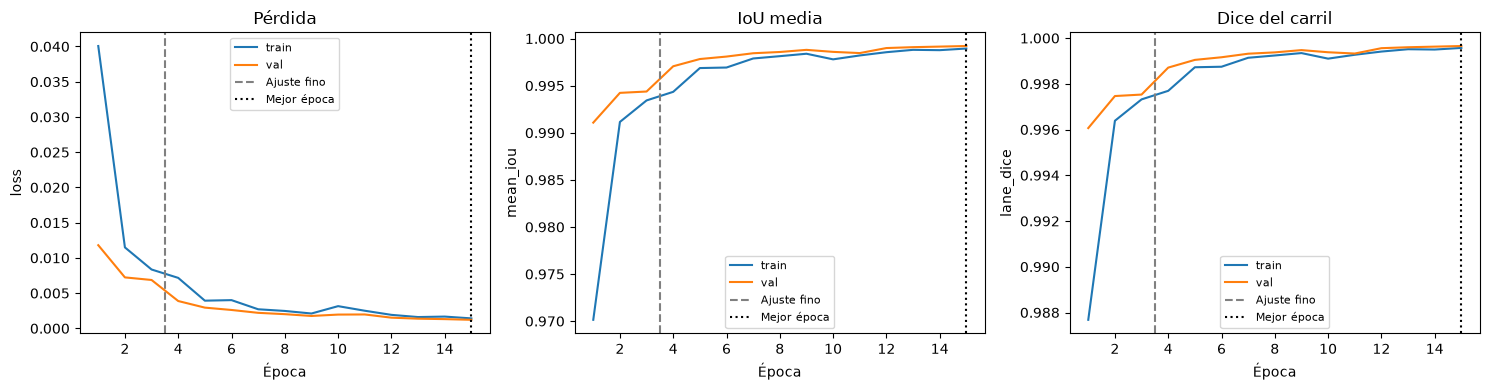

,epoch,phase,learning_rate,train_loss,train_pixel_accuracy,train_mean_iou,train_lane_iou,train_lane_dice,val_loss,val_pixel_accuracy,val_mean_iou,val_lane_iou,val_lane_dice,seconds
0,1,decoder,0.00100,0.040066,0.985371,0.970144,0.975661,0.987680,0.011804,0.995585,0.991077,0.992160,0.996065,38.637020
1,2,decoder,0.00100,0.011490,0.995710,0.991151,0.992796,0.996385,0.007234,0.997154,0.994237,0.994944,0.997466,38.709578
2,3,decoder,0.00100,0.008354,0.996820,0.993433,0.994655,0.997320,0.006868,0.997225,0.994379,0.995074,0.997531,39.727053
3,4,fine_tuning,0.00006,0.007165,0.997263,0.994346,0.995398,0.997694,0.003881,0.998550,0.997060,0.997422,0.998710,65.229107
4,5,fine_tuning,0.00006,0.003931,0.998487,0.996871,0.997453,0.998725,0.002944,0.998930,0.997829,0.998096,0.999047,65.202171
5,6,fine_tuning,0.00006,0.004008,0.998515,0.996927,0.997499,0.998748,0.002611,0.999059,0.998091,0.998326,0.999162,65.252744
6,7,fine_tuning,0.00006,0.002711,0.998979,0.997887,0.998280,0.999140,0.002205,0.999233,0.998444,0.998635,0.999317,65.357457
7,8,fine_tuning,0.00006,0.002473,0.999098,0.998133,0.998481,0.999240,0.002016,0.999298,0.998576,0.998751,0.999375,65.106252
8,9,fine_tuning,0.00006,0.002110,0.999223,0.998391,0.998691,0.999345,0.001761,0.999410,0.998803,0.998950,0.999475,65.060839
9,10,fine_tuning,0.00006,0.003155,0.998934,0.997795,0.998205,0.999102,0.001957,0.999305,0.998589,0.998763,0.999381,65.217753


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ['loss', 'mean_iou', 'lane_dice'], ['Pérdida', 'IoU media', 'Dice del carril']):
    for split in ['train', 'val']:
        ax.plot(history.epoch, history[f'{split}_{metric}'], label=split)
    ax.axvline(config['head_epochs'] + 0.5, color='gray', ls='--', label='Ajuste fino')
    ax.axvline(metrics['best_epoch'], color='black', ls=':', label='Mejor época')
    ax.set(xlabel='Época', ylabel=metric, title=title)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(history)

## Evaluación en prueba
Las filas de la matriz representan la etiqueta real y las columnas la predicción. Cada elemento cuenta píxeles. Para el carril, TP son píxeles correctamente predichos como carril, FP son píxeles de fondo predichos como carril y FN son píxeles de carril predichos como fondo. IoU = TP / (TP + FP + FN); Dice = 2 TP / (2 TP + FP + FN).

In [4]:
test = metrics['test']
matrix = np.array(test['confusion_matrix'])
display(pd.DataFrame(matrix, index=['Real: fondo', 'Real: carril'], columns=['Predicho: fondo', 'Predicho: carril']))
tp, fp, fn = matrix[1, 1], matrix[0, 1], matrix[1, 0]
assert np.isclose(tp / (tp + fp + fn), test['lane_iou'])
display(pd.DataFrame(test['per_class']).T)
display(pd.Series({k: test[k] for k in ['samples', 'loss', 'pixel_accuracy', 'mean_iou', 'lane_iou', 'lane_dice']}, name='Prueba').to_frame())

,Predicho: fondo,Predicho: carril
Real: fondo,14480664,8945
Real: carril,8837,20890994


,iou,dice,precision,recall,support_pixels
background,0.998774,0.999386,0.999390,0.999383,14489609.0
lane,0.999150,0.999575,0.999572,0.999577,20899831.0


,Prueba
samples,576.000000
loss,0.001494
pixel_accuracy,0.999498
mean_iou,0.998962
lane_iou,0.999150
lane_dice,0.999575


## Resultados por pista
Comparar pistas completas ayuda a detectar condiciones de trazado o apariencia que los promedios globales ocultan. Los conteos se acumulan antes de calcular IoU; la media de IoU por imagen puede dar otro valor.

In [5]:
from segformer_utils import metrics_from_confusion
per_track = []
for track, rows in predictions.groupby('track_id'):
    counts = rows[['tn', 'fp', 'fn', 'tp']].sum().to_numpy().reshape(2, 2)
    result = metrics_from_confusion(counts)
    per_track.append({'track_id': track, 'samples': len(rows), 'lane_iou': result['lane_iou'], 'mean_iou': result['mean_iou'], 'lane_dice': result['lane_dice']})
display(pd.DataFrame(per_track).sort_values('lane_iou'))

,track_id,samples,lane_iou,mean_iou,lane_dice
3,track_029,96,0.998999,0.998890,0.999499
0,track_026,96,0.999004,0.998714,0.999502
1,track_027,96,0.999072,0.998935,0.999536
4,track_030,96,0.999138,0.998817,0.999569
5,track_031,96,0.999221,0.999147,0.999610
2,track_028,96,0.999438,0.999225,0.999719


## Inspección de errores
La selección siguiente contiene las cuatro imágenes con menor IoU de carril; no representa una muestra aleatoria. El naranja identifica falso carril y el azul carril omitido. Evaluar si las diferencias se concentran en los bordes o cambian la región transitable de manera relevante.

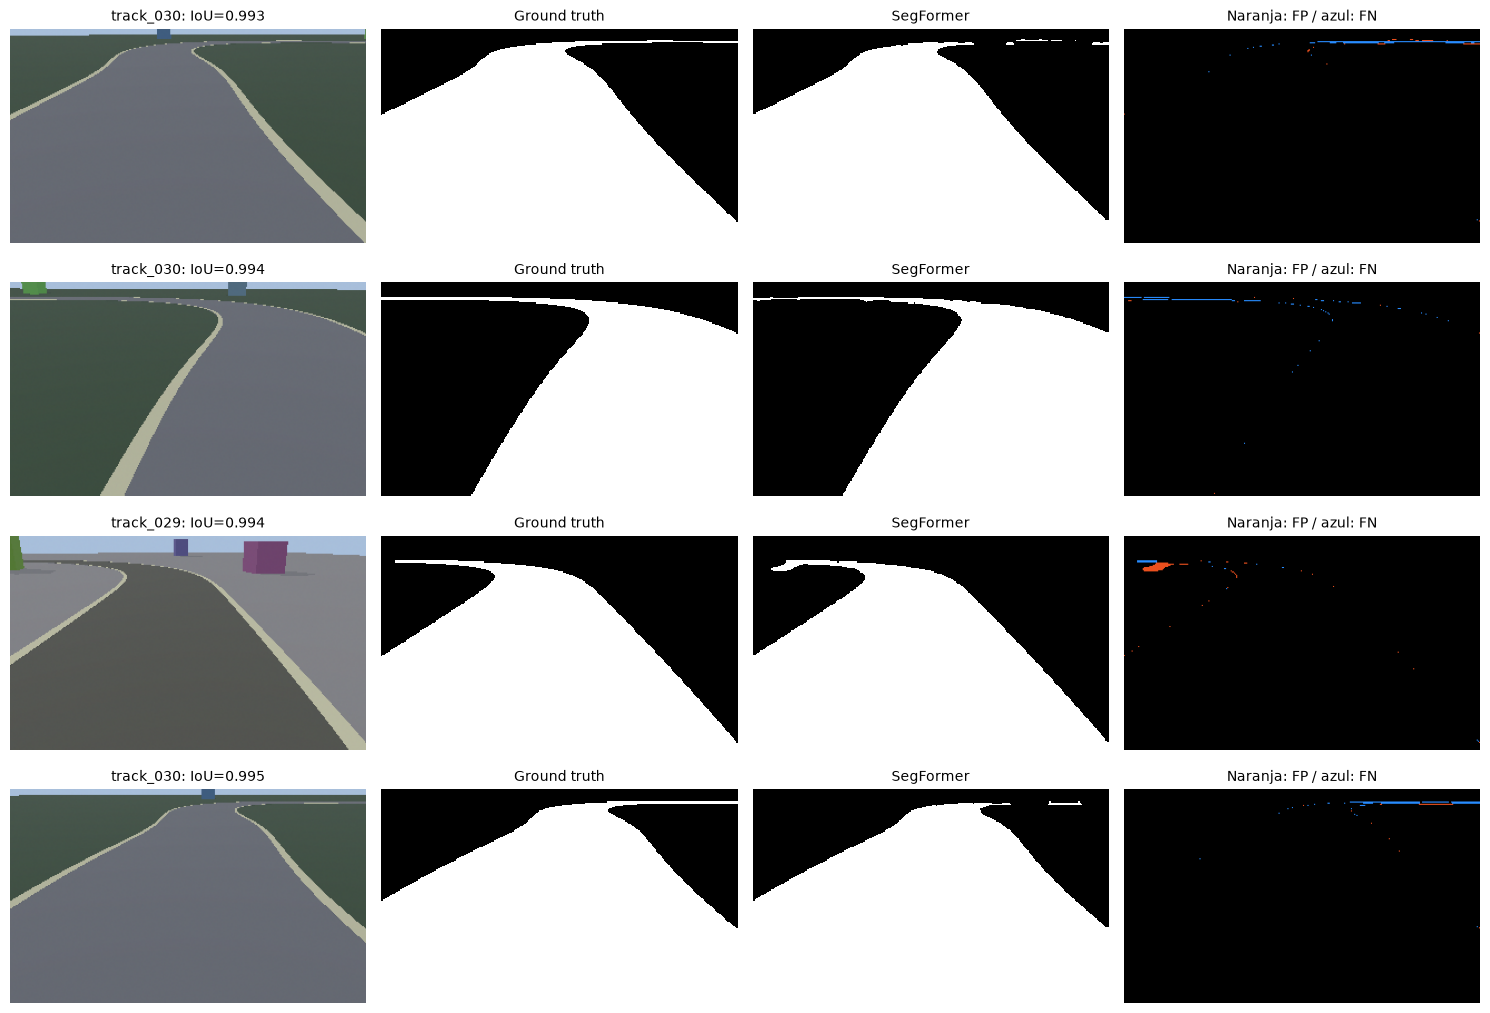

In [6]:
selected = predictions.sort_values('lane_iou').head(4)
fig, axes = plt.subplots(len(selected), 4, figsize=(15, 2.6 * len(selected)), squeeze=False)
for i, row in enumerate(selected.itertuples()):
    rgb = np.asarray(Image.open(dataset / row.image).convert('RGB'))
    target = np.asarray(Image.open(dataset / row.ground_truth))
    predicted = np.asarray(Image.open(run / row.prediction))
    errors = np.zeros_like(rgb)
    errors[(target == 0) & (predicted == 1)] = [235, 80, 30]
    errors[(target == 1) & (predicted == 0)] = [40, 140, 255]
    for j, (image, title) in enumerate([(rgb, f'{row.track_id}: IoU={row.lane_iou:.3f}'), (target, 'Ground truth'), (predicted, 'SegFormer'), (errors, 'Naranja: FP / azul: FN')]):
        if j in [1, 2]: axes[i, j].imshow(image, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        else: axes[i, j].imshow(image)
        axes[i, j].set_title(title, fontsize=10); axes[i, j].axis('off')
plt.tight_layout(); plt.show()

## Interpretación para robótica

1. Relacionar los cambios de las curvas con las dos fases del entrenamiento.
2. Identificar el peor caso por pista y por imagen; distinguir píxeles de borde de regiones completamente equivocadas.
3. Explicar por qué una exactitud por píxel alta no garantiza que el robot complete la pista.
4. Reconocer que la prueba contiene pistas nuevas del mismo generador, no imágenes reales.
5. Conservar la prueba como evaluación final y usar validación para decisiones de configuración.

El seguimiento requiere validar la inferencia, su latencia y el controlador. La exportación a ONNX y la evaluación de navegación complementan las métricas de segmentación.